In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score


In [ ]:
df=pd.read_csv("/content/marketing_campaign.csv",sep='\t')

In [ ]:
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,5,0,0,0,0,0,0,3,11,0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 29 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   2240 non-null   int64  
 1   Year_Birth           2240 non-null   int64  
 2   Education            2240 non-null   object 
 3   Marital_Status       2240 non-null   object 
 4   Income               2216 non-null   float64
 5   Kidhome              2240 non-null   int64  
 6   Teenhome             2240 non-null   int64  
 7   Dt_Customer          2240 non-null   object 
 8   Recency              2240 non-null   int64  
 9   MntWines             2240 non-null   int64  
 10  MntFruits            2240 non-null   int64  
 11  MntMeatProducts      2240 non-null   int64  
 12  MntFishProducts      2240 non-null   int64  
 13  MntSweetProducts     2240 non-null   int64  
 14  MntGoldProds         2240 non-null   int64  
 15  NumDealsPurchases    2240 non-null   i

In [ ]:
df.describe()

,ID,Year_Birth,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
count,2240.000000,2240.000000,2216.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,...,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.0,2240.0,2240.000000
mean,5592.159821,1968.805804,52247.251354,0.444196,0.506250,49.109375,303.935714,26.302232,166.950000,37.525446,...,5.316518,0.072768,0.074554,0.072768,0.064286,0.013393,0.009375,3.0,11.0,0.149107
std,3246.662198,11.984069,25173.076661,0.538398,0.544538,28.962453,336.597393,39.773434,225.715373,54.628979,...,2.426645,0.259813,0.262728,0.259813,0.245316,0.114976,0.096391,0.0,0.0,0.356274
min,0.000000,1893.000000,1730.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
25%,2828.250000,1959.000000,35303.000000,0.000000,0.000000,24.000000,23.750000,1.000000,16.000000,3.000000,...,3.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
50%,5458.500000,1970.000000,51381.500000,0.000000,0.000000,49.000000,173.500000,8.000000,67.000000,12.000000,...,6.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
75%,8427.750000,1977.000000,68522.000000,1.000000,1.000000,74.000000,504.250000,33.000000,232.000000,50.000000,...,7.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
max,11191.000000,1996.000000,666666.000000,2.000000,2.000000,99.000000,1493.000000,199.000000,1725.000000,259.000000,...,20.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,3.0,11.0,1.000000


In [ ]:
df.shape

(2240, 29)

In [ ]:
data=df.copy()
data["Dt_Customer"]=pd.to_datetime(data["Dt_Customer"],dayfirst=True,errors='coerce')
latest_date=data["Dt_Customer"].max()
data["Customer_Tenure_Days"]=(latest_date-data["Dt_Customer"]).dt.days

data=data.drop(
    columns=["ID","Dt_Customer","z_CostContact","z_Revenue","Response"],
    errors="ignore"
)

In [ ]:
numeric_cols=data.select_dtypes(include=np.number).columns.tolist()
categorical_cols=data.select_dtypes(include="object").columns.tolist()

numeric_pipelines=Pipeline([
("imputer",SimpleImputer(strategy="median")),
 ("scaler",StandardScaler())
])


In [ ]:
categorical_pipeline=Pipeline([
    ("imputer",SimpleImputer(strategy="most_frequent")),
    ("onehot",OneHotEncoder(handle_unknown="ignore"))
])

In [ ]:
preprocessor=ColumnTransformer([
    ("numeric",numeric_pipelines,numeric_cols),
    ("categorical",categorical_pipeline,categorical_cols)
])

In [ ]:
X=preprocessor.fit_transform(data)
if hasattr(X,"toarray"):
  X=X.toarray()

In [ ]:
print("Rows used:",X.shape[0])
print("Features after encoding:",X.shape[1])
print("Numerical features:",len(numeric_cols))
print("Categorical features:",categorical_cols)

Rows used: 2240
Features after encoding: 38
Numerical features: 25
Categorical features: ['Education', 'Marital_Status']


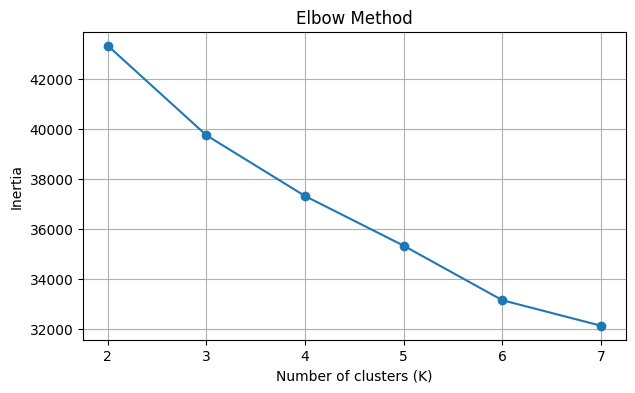

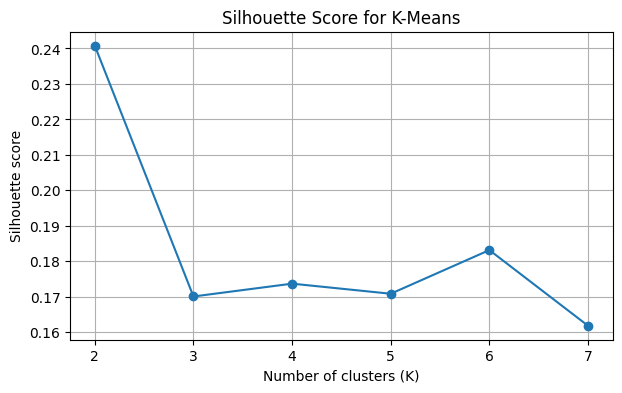

Silhouette scores: {2: np.float64(0.241), 3: np.float64(0.17), 4: np.float64(0.174), 5: np.float64(0.171), 6: np.float64(0.183), 7: np.float64(0.162)}


In [ ]:
inertias = []
silhouette_scores = []
k_values = range(2, 8)

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X)
    inertias.append(model.inertia_)
    silhouette_scores.append(silhouette_score(X, labels))

plt.figure(figsize=(7, 4))
plt.plot(list(k_values), inertias, marker="o")
plt.xlabel("Number of clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(list(k_values), silhouette_scores, marker="o")
plt.xlabel("Number of clusters (K)")
plt.ylabel("Silhouette score")
plt.title("Silhouette Score for K-Means")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

print("Silhouette scores:", {k: round(s, 3) for k, s in zip(k_values, silhouette_scores)})





In [ ]:
kmeans= KMeans(n_clusters=4,random_state=42,n_init=10)
kmeans_labels=kmeans.fit_predict(X)

results=df.copy()
results["KMeans_Cluster"]=kmeans_labels

print("K-Means cluster sizes:")
display(results["KMeans_Cluster"].value_counts().sort_index().rename("Customers").to_frame())

summary_cols=[c for c in [
    "Income", "MntWines", "MntMeatProducts", "MntFishProducts",
    "MntSweetProducts", "MntGoldProds", "NumWebPurchases",
    "NumCatalogPurchases", "NumStorePurchases", "NumWebVisitsMonth",
    "Recency"
] if c in results.columns]
display(results.groupby("KMeans_Cluster")[summary_cols].mean().round(1))

K-Means cluster sizes:


,Customers
KMeans_Cluster,
0,30
1,634
2,1038
3,538


,Income,MntWines,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Recency
KMeans_Cluster,,,,,,,,,,,
0,71054.8,898.7,250.3,38.7,30.6,66.4,4.9,5.2,8.2,5.2,48.7
1,58088.1,456.0,140.2,32.1,24.9,60.2,6.4,3.1,7.8,5.7,48.4
2,34908.5,42.0,23.5,7.0,5.1,15.4,2.1,0.6,3.2,6.4,49.4
3,77694.1,597.1,470.6,102.6,71.9,79.0,5.1,6.1,8.3,2.7,49.5


In [ ]:
dbscan = DBSCAN(eps=4.0, min_samples=10)
dbscan_labels = dbscan.fit_predict(X)
results["DBSCAN_Cluster"] = dbscan_labels

n_clusters = len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0)
n_noise = int(np.sum(dbscan_labels == -1))

print("DBSCAN clusters found (excluding noise):", n_clusters)
print("Customers labelled as noise:", n_noise)
print("Noise percentage:", round(100 * n_noise / len(dbscan_labels), 2), "%")
print("\nDBSCAN label counts (-1 means noise):")
display(pd.Series(dbscan_labels, name="DBSCAN_Cluster").value_counts().sort_index().to_frame())


DBSCAN clusters found (excluding noise): 5
Customers labelled as noise: 255
Noise percentage: 11.38 %

DBSCAN label counts (-1 means noise):


,count
DBSCAN_Cluster,
-1,255
0,1900
1,41
2,10
3,11
4,23


Explained variance ratio: [0.265 0.086]
Total variance shown in 2D: 35.08 %


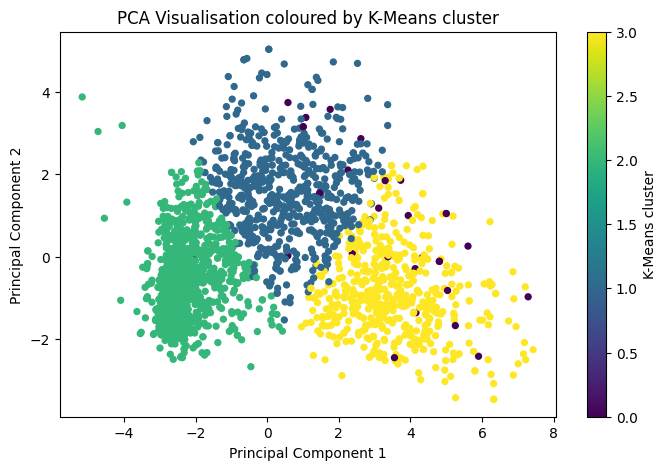

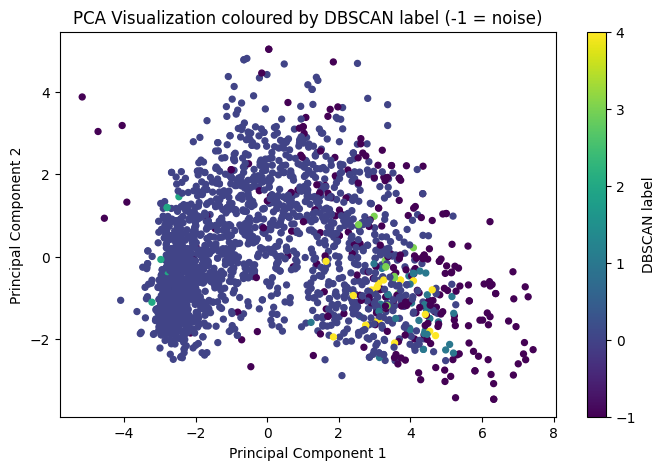

In [ ]:
pca=PCA(n_components=2,random_state=42)
X_pca=pca.fit_transform(X)

print("Explained variance ratio:",np.round(pca.explained_variance_ratio_, 3))
print("Total variance shown in 2D:",round(pca.explained_variance_ratio_.sum() * 100, 2), "%")

plt.figure(figsize=(8,5))
scatter=plt.scatter(X_pca[:,0],X_pca[:, 1],c=kmeans_labels,s=18)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA Visualisation coloured by K-Means cluster")
plt.colorbar(scatter,label="K-Means cluster")
plt.show()
plt.figure(figsize=(8, 5))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=dbscan_labels, s=18)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA Visualization coloured by DBSCAN label (-1 = noise)")
plt.colorbar(scatter, label="DBSCAN label")
plt.show()

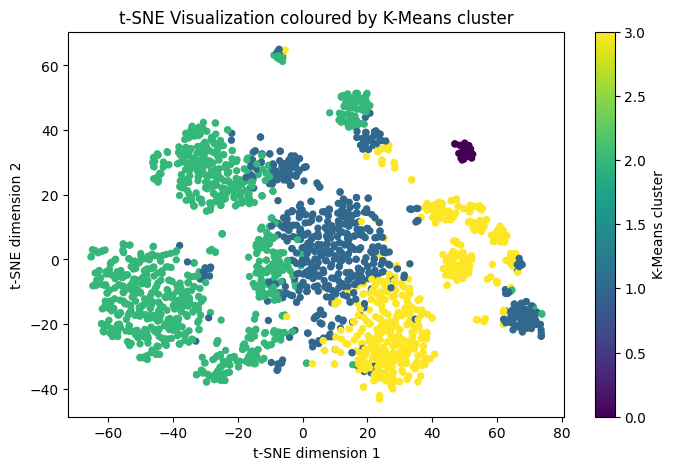

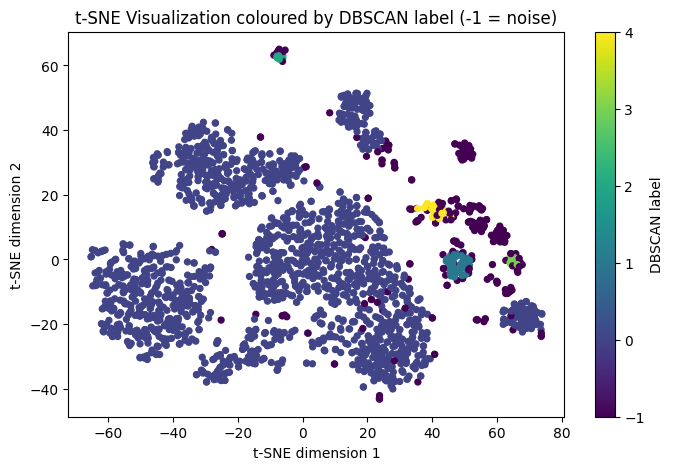

In [ ]:
tsne = TSNE(
    n_components=2,
    perplexity=30,
    learning_rate="auto",
    init="pca",
    random_state=42
)
X_tsne = tsne.fit_transform(X)

plt.figure(figsize=(8, 5))
scatter = plt.scatter(X_tsne[:, 0], X_tsne[:, 1], c=kmeans_labels, s=18)
plt.xlabel("t-SNE dimension 1")
plt.ylabel("t-SNE dimension 2")
plt.title("t-SNE Visualization coloured by K-Means cluster")
plt.colorbar(scatter, label="K-Means cluster")
plt.show()

plt.figure(figsize=(8, 5))
scatter = plt.scatter(X_tsne[:, 0], X_tsne[:, 1], c=dbscan_labels, s=18)
plt.xlabel("t-SNE dimension 1")
plt.ylabel("t-SNE dimension 2")
plt.title("t-SNE Visualization coloured by DBSCAN label (-1 = noise)")
plt.colorbar(scatter, label="DBSCAN label")
plt.show()
